In [35]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense

print("TensorFlow:", tf.__version__)

TensorFlow: 2.15.1


In [36]:
data = pd.read_csv("creditcard.csv")

print("Dataset shape:", data.shape)
display(data.head())

Dataset shape: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [37]:
print(data.info())
print("\nMissing values:")
print(data.isnull().sum().sum())
print("\nDuplicate rows:", data.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

In [38]:
data = data.drop_duplicates().copy()
print("Dataset shape after removing duplicates:", data.shape)

Dataset shape after removing duplicates: (283726, 31)


In [39]:
print(data["Class"].value_counts())


Class
0    283253
1       473
Name: count, dtype: int64


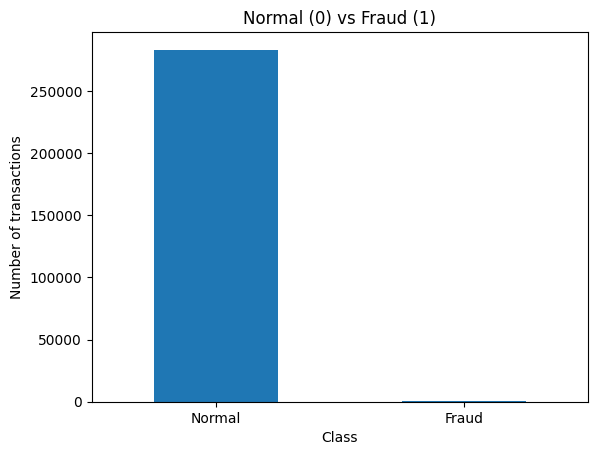

In [40]:
data["Class"].value_counts().sort_index().plot(kind="bar")
plt.xlabel("Class")
plt.ylabel("Number of transactions")
plt.title("Normal (0) vs Fraud (1)")
plt.xticks([0, 1], ["Normal", "Fraud"], rotation=0)
plt.show()


In [41]:
X = data.drop("Class", axis=1)
y = data["Class"]

print("Features:", X.shape)
print("Target:", y.shape)

Features: (283726, 30)
Target: (283726,)


In [42]:
print("Remaining duplicate rows:", data.duplicated().sum())

Remaining duplicate rows: 0


In [43]:
X = data.drop("Class", axis=1)
y = data["Class"]


In [44]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

X_train: (226980, 30)
X_test: (56746, 30)


In [45]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training shape:", X_train_scaled.shape)
print("Testing shape:", X_test_scaled.shape)


Training shape: (226980, 30)
Testing shape: (56746, 30)


In [46]:
X_train_scaled = X_train_scaled.astype("float32")
X_test_scaled = X_test_scaled.astype("float32")

In [47]:
X_train_normal = X_train_scaled[y_train.to_numpy() == 0]

print("Normal transactions used for training:", X_train_normal.shape)

Normal transactions used for training: (226602, 30)


In [48]:
input_features = X_train_normal.shape[1]

autoencoder = Sequential([
    Input(shape=(input_features,)),
    Dense(64, activation="relu"),
    Dense(32, activation="relu"),
    Dense(16, activation="relu"),
    Dense(8, activation="relu"),
    Dense(16, activation="relu"),
    Dense(32, activation="relu"),
    Dense(64, activation="relu"),
    Dense(input_features, activation="linear")
])

autoencoder.summary()

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense_8 (Dense)             (None, 64)                1984      
                                                                 
 dense_9 (Dense)             (None, 32)                2080      
                                                                 
 dense_10 (Dense)            (None, 16)                528       
                                                                 
 dense_11 (Dense)            (None, 8)                 136       
                                                                 
 dense_12 (Dense)            (None, 16)                144       
                                                                 
 dense_13 (Dense)            (None, 32)                544       
                                                                 
 dense_14 (Dense)            (None, 64)               

In [49]:
autoencoder.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="mse",
    metrics=["mae"]
)

print("Autoencoder compiled.")


Autoencoder compiled.


In [50]:
history = autoencoder.fit(
    X_train_normal,
    X_train_normal,
    epochs=5,
    batch_size=2048,
    validation_split=0.20,
    shuffle=True,
    verbose=1
)


Epoch 1/5
89/89 [==============================] - 2s 8ms/step - loss: 0.8776 - mae: 0.6384 - val_loss: 0.7672 - val_mae: 0.6022
Epoch 2/5
89/89 [==============================] - 0s 5ms/step - loss: 0.6730 - mae: 0.5645 - val_loss: 0.6005 - val_mae: 0.5321
Epoch 3/5
89/89 [==============================] - 0s 5ms/step - loss: 0.5486 - mae: 0.5112 - val_loss: 0.5068 - val_mae: 0.4921
Epoch 4/5
89/89 [==============================] - 0s 5ms/step - loss: 0.4836 - mae: 0.4814 - val_loss: 0.4589 - val_mae: 0.4709
Epoch 5/5
89/89 [==============================] - 0s 5ms/step - loss: 0.4414 - mae: 0.4627 - val_loss: 0.4258 - val_mae: 0.4558


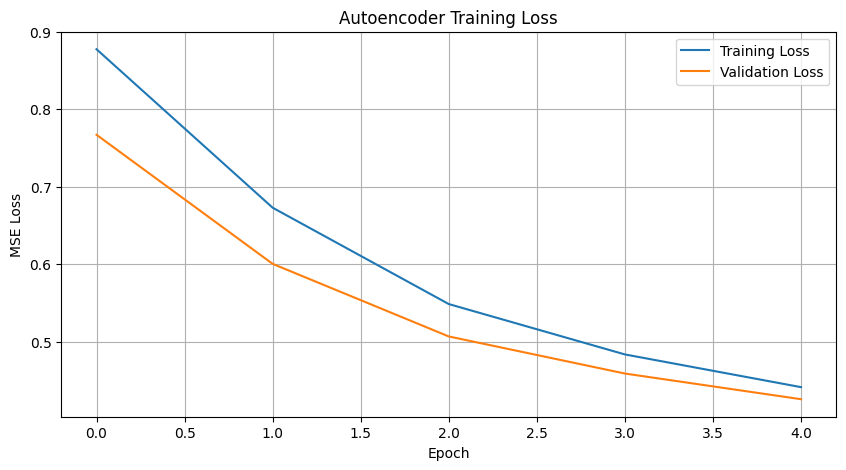

In [51]:
plt.figure(figsize=(10, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Autoencoder Training Loss")
plt.legend()
plt.grid()
plt.show()

In [52]:
X_train_reconstructed = autoencoder.predict(
    X_train_normal, batch_size=256, verbose=0
)

print("Original shape:", X_train_normal.shape)
print("Reconstructed shape:", X_train_reconstructed.shape)


2026-10-21 15:01:41.967293: W external/local_tsl/tsl/framework/cpu_allocator_impl.cc:83] Allocation of 27192240 exceeds 10% of free system memory.


Original shape: (226602, 30)
Reconstructed shape: (226602, 30)


2026-10-21 15:01:43.405920: W external/local_tsl/tsl/framework/cpu_allocator_impl.cc:83] Allocation of 27192240 exceeds 10% of free system memory.


In [53]:
normal_error = np.mean(
    np.square(X_train_normal - X_train_reconstructed),
    axis=1
)

print(normal_error[:10])

[0.51197034 0.32757425 0.34982964 0.6114865  0.19892572 0.4579008
 0.21489139 0.52103245 0.2571923  0.40482792]


In [54]:
threshold = np.percentile(normal_error, 95)
print("Anomaly threshold:", threshold)

Anomaly threshold: 1.0565899074077594


In [55]:
X_test_reconstructed = autoencoder.predict(
    X_test_scaled, batch_size=256, verbose=0
)

print("Test reconstructed shape:", X_test_reconstructed.shape)

Test reconstructed shape: (56746, 30)


In [57]:
test_error = np.mean(
    np.square(X_test_scaled - X_test_reconstructed),
    axis=1
)

print(test_error[:10])


[0.13134232 0.2593019  0.7595765  0.18091066 0.34670395 0.14604361
 0.420088   0.3108584  0.4270979  0.43242615]


In [56]:
y_pred = (
    test_error > threshold
).astype(int)

print("Predicted classes:")
print(y_pred[:20])


Predicted classes:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


In [58]:
y_pred = (test_error > threshold).astype(int)
print(y_pred[:20])

[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


In [59]:
results = pd.DataFrame({
    "Actual_Class": y_test.to_numpy(),
    "Reconstruction_Error": test_error,
    "Predicted_Class": y_pred
})

display(results.head(20))

,Actual_Class,Reconstruction_Error,Predicted_Class
0,0,0.131342,0
1,0,0.259302,0
2,0,0.759576,0
3,0,0.180911,0
4,0,0.346704,0
5,0,0.146044,0
6,0,0.420088,0
7,0,0.310858,0
8,0,0.427098,0
9,0,0.432426,0


In [60]:
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)

Accuracy: 0.9498466852289148


In [61]:
cm = confusion_matrix(y_test, y_pred)
print(cm)

[[53823  2828]
 [   18    77]]


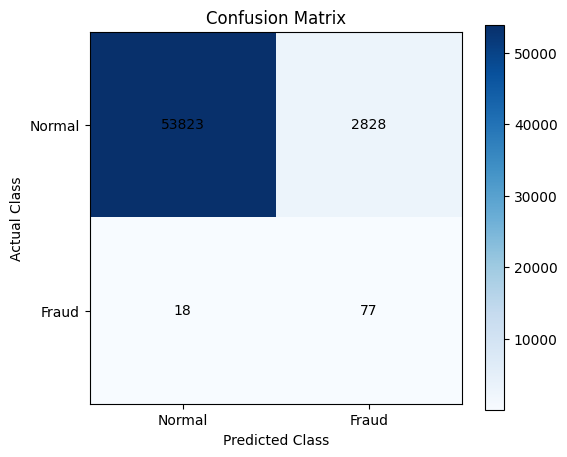

In [62]:

plt.figure(figsize=(6, 5))
plt.imshow(cm, cmap="Blues")
plt.colorbar()
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Confusion Matrix")
plt.xticks([0, 1], ["Normal", "Fraud"])
plt.yticks([0, 1], ["Normal", "Fraud"])

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha="center", va="center")

plt.show()

In [63]:
print(classification_report(
    y_test,
    y_pred,
    target_names=["Normal", "Fraud"],
    zero_division=0
))


              precision    recall  f1-score   support

      Normal       1.00      0.95      0.97     56651
       Fraud       0.03      0.81      0.05        95

    accuracy                           0.95     56746
   macro avg       0.51      0.88      0.51     56746
weighted avg       1.00      0.95      0.97     56746



In [64]:
fraud_transactions = results[results["Predicted_Class"] == 1]

print("Number of detected anomalies:", len(fraud_transactions))
display(fraud_transactions.head(20))

Number of detected anomalies: 2905


,Actual_Class,Reconstruction_Error,Predicted_Class
34,0,1.127090,1
56,0,2.052584,1
100,0,1.603294,1
146,0,1.297858,1
156,0,1.102352,1
171,0,1.154366,1
187,0,1.358234,1
198,0,6.833626,1
209,0,1.268274,1
240,0,1.149591,1
